# 04 — Threat Detection & SOC Alert Analysis

## Project objective
This notebook reviews the outputs of the rule-based threat-detection pipeline and the generated SOC alerts. It is designed to **consume existing outputs**; it does not rerun detection across the 4.1-million-row dataset.

## Questions explored
1. Did the detection and alert-generation outputs get created?
2. How are detected incidents distributed by severity and risk score?
3. Which detection categories and rules appear most often?
4. What do representative SOC alerts contain?
5. What limitations must an analyst consider?

**Important:** The risk score is a heuristic prioritization score, not a probability of compromise. Automated alerts require analyst validation.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

DETECTION_FILE = PROJECT_ROOT / "reports" / "incident_reports" / "incident_detection_summary.csv"
ALERTS_CSV = PROJECT_ROOT / "reports" / "soc_alerts" / "soc_alerts.csv"
ALERTS_JSONL = PROJECT_ROOT / "reports" / "soc_alerts" / "soc_alerts.jsonl"
ALERT_SUMMARY = PROJECT_ROOT / "reports" / "soc_alerts" / "alert_generation_summary.json"
INCIDENT_SUMMARY = PROJECT_ROOT / "reports" / "incident_reports" / "generated" / "incident_reports_summary.csv"

print("Project root:", PROJECT_ROOT)
for path in [DETECTION_FILE, ALERTS_CSV, ALERTS_JSONL, ALERT_SUMMARY, INCIDENT_SUMMARY]:
    print(("FOUND  " if path.exists() else "MISSING"), path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path)

Project root: D:\Microsoft-SOC-Project
MISSING reports\incident_reports\incident_detection_summary.csv
FOUND   reports\soc_alerts\soc_alerts.csv
FOUND   reports\soc_alerts\soc_alerts.jsonl
FOUND   reports\soc_alerts\alert_generation_summary.json
FOUND   reports\incident_reports\generated\incident_reports_summary.csv


## 1. Load existing pipeline outputs

The detection summary and SOC alert CSV are loaded as strings first to avoid mixed-type inference problems. Numeric fields are converted explicitly in later cells.

In [2]:
# The detection summary is optional for this notebook. The SOC alert CSV is the primary input.
if DETECTION_FILE.exists():
    detection = pd.read_csv(DETECTION_FILE, low_memory=False)
    print("Detection summary shape:", detection.shape)
    print("Detection summary columns:")
    print(detection.columns.tolist())
else:
    detection = None
    print("Detection summary CSV not found at:", DETECTION_FILE)
    print("Continuing with the generated SOC alert outputs.")

if not ALERTS_CSV.exists():
    raise FileNotFoundError(
        f"SOC alerts CSV not found: {ALERTS_CSV}. "
        "Confirm that src/soc_alert_generator.py has been run."
    )

alerts = pd.read_csv(ALERTS_CSV, dtype=str, low_memory=False)

print("\\nSOC alerts shape:", alerts.shape)
print("SOC alert columns:")
print(alerts.columns.tolist())
display(alerts.head(3))

Detection summary CSV not found at: D:\Microsoft-SOC-Project\reports\incident_reports\incident_detection_summary.csv
Continuing with the generated SOC alert outputs.
\nSOC alerts shape: (193613, 17)
SOC alert columns:
['AlertID', 'IncidentID', 'Severity', 'RiskScore', 'MatchedRecords', 'UniqueAlerts', 'FirstSeen', 'LastSeen', 'DetectionRules', 'Categories', 'MITRETechniques', 'EntityTypes', 'EvidenceRoles', 'AlertTitleIDs', 'DetectorIDs', 'RecommendedActions', 'Disposition']


,AlertID,IncidentID,Severity,RiskScore,MatchedRecords,UniqueAlerts,FirstSeen,LastSeen,DetectionRules,Categories,MITRETechniques,EntityTypes,EvidenceRoles,AlertTitleIDs,DetectorIDs,RecommendedActions,Disposition
0,SOC-3,3,Critical,100,19154,1755,2024-06-03T21:53:10Z,2024-06-14T12:54:12Z,Credential Access Activity; Defense Evasion Ac...,CredentialAccess; DefenseEvasion; Discovery; E...,T1027; T1105; T1566.001,File; Ip; Machine; MailMessage; Process; Regis...,Impacted; Related,1014; 119; 12232; 12846; 13840; 15330; 15478; ...,1011; 1065; 1079; 1104; 1242; 138; 1430; 1439;...,Review authentication activity for affected ac...,Pending analyst review
1,SOC-8,8,Critical,100,11199,768,2024-06-08T17:11:27Z,2024-06-11T20:02:55Z,Credential Access Activity; Defense Evasion Ac...,CredentialAccess; DefenseEvasion; Discovery; E...,T1027; T1105; T1566.001,File; Ip; Machine; MailMessage; Process; Regis...,Impacted; Related,1014; 12524; 12846; 13840; 14349; 1459; 1483; ...,1011; 1104; 126; 135; 1400; 1430; 160; 166; 19...,Review authentication activity for affected ac...,Pending analyst review
2,SOC-13,13,Critical,100,10340,68,2024-06-06T09:32:36Z,2024-06-06T22:43:06Z,Credential Access Activity; Initial Access Act...,CredentialAccess; InitialAccess,T1110.001; T1566; T1566.002,CloudApplication; File; Ip; MailCluster; MailM...,Impacted; Related,1; 22; 23; 389; 48,1; 33; 35; 377; 66,Review authentication activity for affected ac...,Pending analyst review


## 2. Check alert-generation summary

This reads the generator's recorded summary, if available. It provides a quick consistency check against the CSV output.

In [3]:
if ALERT_SUMMARY.exists():
    with ALERT_SUMMARY.open("r", encoding="utf-8") as f:
        alert_generation_summary = json.load(f)
    print(json.dumps(alert_generation_summary, indent=2))
else:
    print("Alert-generation summary JSON is not available.")

{
  "TotalAlertsGenerated": 193613,
  "SeverityDistribution": {
    "Critical": 100482,
    "High": 52901,
    "Medium": 40230
  },
  "OutputFiles": [
    "soc_alerts.csv",
    "soc_alerts.jsonl"
  ],
  "RiskScoreMeaning": "Heuristic prioritization score, not probability of compromise",
  "Status": "Generated - pending analyst review"
}


## 3. Severity distribution

Severity counts describe how the rule-based system prioritized generated alerts. They do **not** represent confirmed incidents or measured compromise probability.

,Alert count
Severity,
Critical,100482
High,52901
Medium,40230


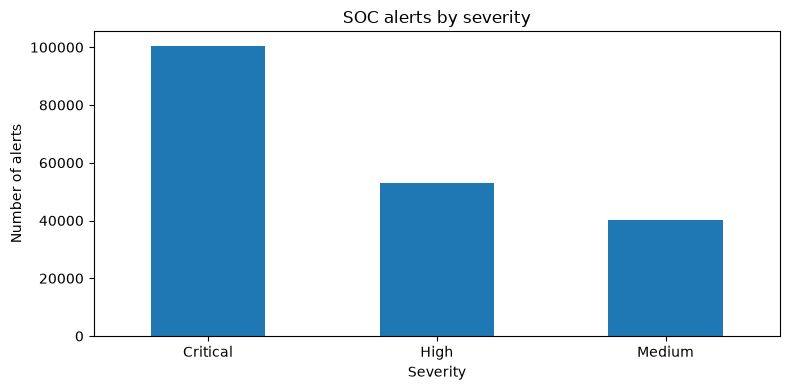

In [4]:
severity_col = next((c for c in alerts.columns if c.lower() == "severity"), None)
if severity_col is None:
    print("No Severity column found. Review the alert schema above.")
else:
    severity_counts = alerts[severity_col].fillna("Unknown").value_counts()
    display(severity_counts.rename("Alert count").to_frame())
    ax = severity_counts.plot(kind="bar", figsize=(8, 4), rot=0)
    ax.set_title("SOC alerts by severity")
    ax.set_xlabel("Severity")
    ax.set_ylabel("Number of alerts")
    plt.tight_layout()
    plt.show()

## 4. Risk-score distribution

The score is a heuristic prioritization value. A high score should trigger review, not be interpreted as a calibrated probability.

,Risk score
count,193613.000000
mean,82.275286
std,15.919260
min,50.000000
25%,85.000000
50%,90.000000
75%,90.000000
max,100.000000


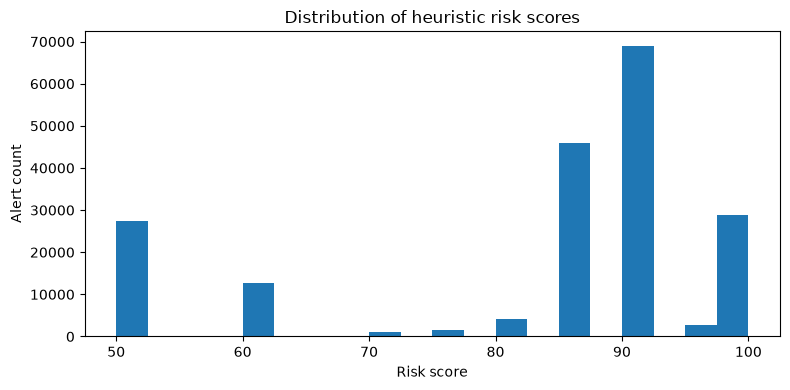

In [5]:
score_col = next((c for c in alerts.columns if c.lower() in {"riskscore", "risk_score"}), None)
if score_col is None:
    print("No risk-score column found. Review the alert schema above.")
else:
    scores = pd.to_numeric(alerts[score_col], errors="coerce").dropna()
    display(scores.describe().to_frame("Risk score"))
    ax = scores.plot(kind="hist", bins=20, figsize=(8, 4))
    ax.set_title("Distribution of heuristic risk scores")
    ax.set_xlabel("Risk score")
    ax.set_ylabel("Alert count")
    plt.tight_layout()
    plt.show()

## 5. Detection categories and rules

The SOC alert CSV stores some fields as serialized lists. The helper below safely parses JSON-style lists and, where necessary, semicolon-separated values. Counts are alert-level occurrences, not unique affected entities.

In [6]:
def parse_list_cell(value):
    if pd.isna(value) or str(value).strip() == "":
        return []
    text = str(value).strip()
    try:
        parsed = json.loads(text)
        if isinstance(parsed, list):
            return [str(x) for x in parsed]
    except (json.JSONDecodeError, TypeError):
        pass
    return [part.strip() for part in text.split(";") if part.strip()]

def count_list_values(series):
    values = []
    for cell in series:
        values.extend(parse_list_cell(cell))
    return pd.Series(values, dtype="object").value_counts()

for candidate in ["Categories", "DetectionRules", "MITRETechniques"]:
    col = next((c for c in alerts.columns if c.lower() == candidate.lower()), None)
    print(f"\n{candidate}:")
    if col is None:
        print("Column not found.")
        continue
    counts = count_list_values(alerts[col])
    display(counts.head(15).rename("Occurrences").to_frame())


Categories:


,Occurrences
InitialAccess,107565
Exfiltration,38030
CommandAndControl,33477
Execution,17603
CredentialAccess,9501
Malware,5119
Impact,4738
Persistence,2430
DefenseEvasion,2088
LateralMovement,1821



DetectionRules:


,Occurrences
Initial Access Activity,107565
Cloud Account Abuse,39751
Possible Data Exfiltration,38030
Command and Control Activity,33477
Phishing Activity,19939
Execution Activity,17603
Spearphishing Link,14743
Credential Access Activity,9501
Malware-Related Activity,5119
Impact Activity,4738



MITRETechniques:


,Occurrences
T1078.004,39751
T1566,19939
T1566.002,14743
T1566.001,4316
T1078,2862
T1110,2852
T1110.003,2425
T1110.001,2351
T1059.005,1480
T1071,1161


## 6. Timeline coverage

This section summarizes the alert timeline if `FirstSeen` is present. It does not infer causality or an attack sequence.

Valid FirstSeen timestamps: 193613
Earliest: 2023-11-22 15:55:05+00:00
Latest: 2024-06-17 13:30:09+00:00


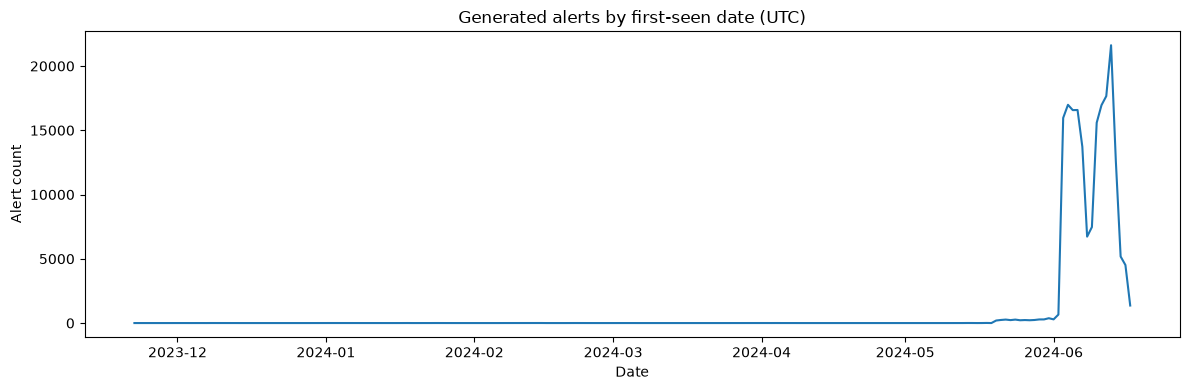

In [7]:
first_seen_col = next((c for c in alerts.columns if c.lower() == "firstseen"), None)
if first_seen_col is None:
    print("FirstSeen column not found.")
else:
    first_seen = pd.to_datetime(alerts[first_seen_col], errors="coerce", utc=True)
    print("Valid FirstSeen timestamps:", int(first_seen.notna().sum()))
    print("Earliest:", first_seen.min())
    print("Latest:", first_seen.max())
    daily = first_seen.dropna().dt.date.value_counts().sort_index()
    if not daily.empty:
        ax = daily.plot(figsize=(12, 4))
        ax.set_title("Generated alerts by first-seen date (UTC)")
        ax.set_xlabel("Date")
        ax.set_ylabel("Alert count")
        plt.tight_layout()
        plt.show()

## 7. Representative alert review

Inspect one alert record without treating its automated fields as a confirmed investigation finding.

In [8]:
if not alerts.empty:
    display(alerts.iloc[0].to_frame("Value"))
else:
    print("SOC alert file contains no rows.")

,Value
AlertID,SOC-3
IncidentID,3
Severity,Critical
RiskScore,100
MatchedRecords,19154
UniqueAlerts,1755
FirstSeen,2024-06-03T21:53:10Z
LastSeen,2024-06-14T12:54:12Z
DetectionRules,Credential Access Activity; Defense Evasion Ac...
Categories,CredentialAccess; DefenseEvasion; Discovery; E...


## 8. Related evaluation and investigation artifacts

The project contains separate evaluation and exfiltration-investigation outputs. This cell lists available files so the analyst can inspect the actual artifacts without assuming filenames or metrics that may not exist.

In [9]:
for folder in [
    PROJECT_ROOT / "reports" / "incident_reports",
    PROJECT_ROOT / "reports" / "exfiltration_investigation",
]:
    print(f"\n{folder.relative_to(PROJECT_ROOT)}")
    if folder.exists():
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                print(f"  {path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size:,} bytes)")
    else:
        print("  Folder not found.")


reports\incident_reports
  reports\incident_reports\generated\incident_reports_summary.csv  (20,851,622 bytes)
  reports\incident_reports\generated\markdown\SOC-11.md  (2,781 bytes)
  reports\incident_reports\generated\markdown\SOC-13.md  (2,716 bytes)
  reports\incident_reports\generated\markdown\SOC-25.md  (2,685 bytes)
  reports\incident_reports\generated\markdown\SOC-28.md  (2,934 bytes)
  reports\incident_reports\generated\markdown\SOC-3.md  (3,839 bytes)
  reports\incident_reports\generated\markdown\SOC-38.md  (2,826 bytes)
  reports\incident_reports\generated\markdown\SOC-50.md  (2,620 bytes)
  reports\incident_reports\generated\markdown\SOC-57.md  (2,809 bytes)
  reports\incident_reports\generated\markdown\SOC-68.md  (2,626 bytes)
  reports\incident_reports\generated\markdown\SOC-8.md  (4,089 bytes)

reports\exfiltration_investigation
  reports\exfiltration_investigation\exfiltration_alert_title_holdout_results.csv  (158 bytes)
  reports\exfiltration_investigation\exfiltration

## 9. Analyst interpretation and limitations

Record conclusions based on the outputs above. Keep observations separate from hypotheses.

### Interpretation checklist
- [ ] Confirm that alert counts match the alert-generation summary.
- [ ] Review severity and risk-score distributions.
- [ ] Identify frequently triggered categories and rules.
- [ ] Inspect representative alerts and their supporting evidence.
- [ ] Compare detection results with the project's evaluation report.
- [ ] Record false-positive patterns and data-quality limitations.

### Known project limitations
1. Detection is rule-based and depends on the implemented category and MITRE technique rules.
2. Risk score is a prioritization heuristic, not a probability of compromise.
3. `IncidentGrade` is used for evaluation, not as an input to detection rules.
4. Numeric AlertTitle and Detector identifiers have no verified descriptive mapping in this project.
5. Incident labels have documented conflicts; evaluation must account for label quality and the evaluated subset.
6. Existing evaluation results showed limited precision. The detection logic should not be described as production-ready.
7. Co-occurring rules do not, by themselves, prove a causal attack chain.

### Conclusion
This notebook documents and inspects the existing detection outputs. It does not independently validate detections against live telemetry, and it does not replace analyst investigation.